In [1]:
import torch
import matplotlib.pyplot as plt

i: 0, fx: -8.488e-01, grad_norm: 4.860e-01
i: 1, fx: -8.718e-01, grad_norm: 4.567e-01
i: 2, fx: -8.919e-01, grad_norm: 4.266e-01
i: 3, fx: -9.095e-01, grad_norm: 3.962e-01
i: 4, fx: -9.246e-01, grad_norm: 3.661e-01
i: 5, fx: -9.375e-01, grad_norm: 3.369e-01
i: 6, fx: -9.484e-01, grad_norm: 3.088e-01
i: 7, fx: -9.575e-01, grad_norm: 2.822e-01
i: 8, fx: -9.651e-01, grad_norm: 2.573e-01
i: 9, fx: -9.714e-01, grad_norm: 2.339e-01
i: 10, fx: -9.766e-01, grad_norm: 2.124e-01
i: 11, fx: -9.809e-01, grad_norm: 1.925e-01
i: 12, fx: -9.845e-01, grad_norm: 1.742e-01
i: 13, fx: -9.874e-01, grad_norm: 1.575e-01
i: 14, fx: -9.897e-01, grad_norm: 1.423e-01
i: 15, fx: -9.916e-01, grad_norm: 1.285e-01
i: 16, fx: -9.932e-01, grad_norm: 1.159e-01
i: 17, fx: -9.945e-01, grad_norm: 1.045e-01
i: 18, fx: -9.955e-01, grad_norm: 9.424e-02
i: 19, fx: -9.964e-01, grad_norm: 8.493e-02
i: 20, fx: -9.971e-01, grad_norm: 7.652e-02
i: 21, fx: -9.976e-01, grad_norm: 6.893e-02
i: 22, fx: -9.981e-01, grad_norm: 6.208e-0

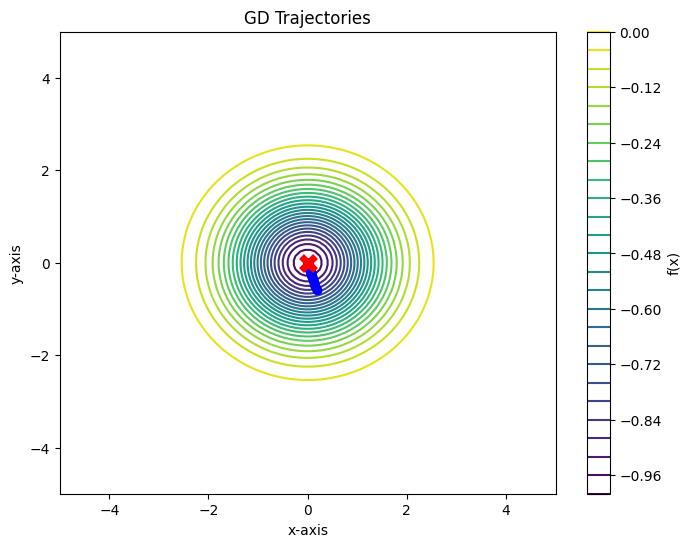

In [2]:
# Setting up the function

# Create the function
def f(x):
  n = x.shape[0]
  assert x.shape == (n,1)

  eponent = -0.5 * torch.sum(x**2)
  output = -torch.exp(eponent)

  output = output.view(1,1)
  assert output.shape == (1,1)
  return output

# Compute the gradient
def grad_f(x):

  # Check that this is true (we set this before the for loop)
  assert x.requires_grad == True
  y = f(x)
  # Make sure output is as scalar
  assert y.shape == (1,1)
  grad_term = torch.autograd.grad(outputs=y, inputs=x, grad_outputs=torch.ones_like(y), create_graph=True)[0]

  # Save space (and get rid of any weird extra stuff)
  y = y.detach()
  x = x.detach()
  #grad_term = grad_term.detach()


  # Make sure the gradient is the same sizeas the input
  assert grad_term.shape == x.shape

  # Return
  return grad_term

  # run gradient descent

def gradient_descent(f, grad_f, step_size, x0, tol=1e-3, max_iters=1000):

  # Save x at each iteration for plotting
  x_hist = []
  # Save f at each iteration for plotting
  f_hist = []
  # Save gradient norm at each iteration for plotting
  # This one is pretty important since we want it to go to zero
  grad_norm_hist = []
  x = x0

  # Set x.requires_grad = True
  x.requires_grad = True

  # Add our initial guess to the histogram data for plotting
  x_hist.append(x0)
  f_hist.append(f(x0))
  grad_fx = grad_f(x0)
  grad_norm_term = torch.norm(grad_fx)
  grad_norm_hist.append(torch.norm(grad_norm_term))

  for i in range(max_iters):
    # Gradient descent update
    x = x - step_size * grad_fx

    # evaluate
    grad_fx = grad_f(x)
    fx = f(x)

    # For plotting
    grad_norm = torch.norm(grad_fx)

    # Store values
    x_hist.append(x.detach())
    f_hist.append(fx.detach())
    grad_norm_hist.append(grad_norm.detach())

    # Print Values
    print('i: %d, fx: %.3e, grad_norm: %.3e' % (i, fx.item(), grad_norm.item()))

    # Check stopping criterion
    if grad_norm <= tol:
      print("converge!")
      break

  # optimal x
  x_opt = x.detach()

  return x_opt, f_hist, grad_norm_hist, x_hist

# Set up optimization parameters (picked randomly)
dim = 2
# Played around to try to find a good step size that converages. This takes some guess work
step_size = 1e-1
max_iters = 1000
# random x
x0 = torch.randn(dim,1)
tol = 1e-3

x_opt1, f_hist1, grad_norm_hist1, x_hist1 = gradient_descent(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)

# Create a 2D grid from -5 to 5

# Define the range and number of points
xx = torch.linspace(-5, 5, 100)
yy = torch.linspace(-5, 5, 100)

## Create a 2D grid
X, Y = torch.meshgrid(xx,yy,indexing='xy') # 'xy' indexing ensures correct indexing for 2D grid

Z = torch.zeros(X.shape)
for i in range(100):
  for j in range(100):
    input_vec = torch.tensor([X[i,j],Y[i,j]]).view(2,1)
    Z[i,j] = f(input_vec).item()

plt.figure(figsize=(8,6))

# Plots the landscape
plt.contour(X,Y,Z,levels=30, cmap='viridis')

#extract x coords
x_coords = [x[0].item() for x in x_hist1]
#extract y coords
y_coords = [x[1].item() for x in x_hist1]

# Plot the gradient descent trajectory
plt.plot(x_coords, y_coords, marker='o', color='blue', label='GD traj 1')

# plot minimizer
plt.plot(0, 0, marker='x', color='red', markersize=10, markeredgewidth=5)


plt.colorbar(label='f(x)')
plt.title('GD Trajectories')
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.show()

In [3]:
# Implementing the Runge-Kutta 4 method

def runge_kutta_4(f, grad_f, step_size, x0, tol=1e-3, max_iters=1000):
    x_hist = []
    f_hist = []
    grad_norm_hist = []

    x = x0.clone().detach().requires_grad_(True)

    x_hist.append(x.detach())
    f_hist.append(f(x).detach())
    grad_fx = grad_f(x)
    grad_norm = torch.norm(grad_fx)
    grad_norm_hist.append(grad_norm.detach())

    for i in range(max_iters):
        # Runge-Kutta 4 integration of dx/dt = -∇f(x)
        k1 = -grad_f(x)
        k2 = -grad_f(x + 0.5 * step_size * k1)
        k3 = -grad_f(x + 0.5 * step_size * k2)
        k4 = -grad_f(x + step_size * k3)

        dx = (step_size / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
        x = x + dx.detach().clone().requires_grad_(True)

        fx = f(x)
        grad_fx = grad_f(x)
        grad_norm = torch.norm(grad_fx)

        x_hist.append(x.detach())
        f_hist.append(fx.detach())
        grad_norm_hist.append(grad_norm.detach())

        print('i: %d, fx: %.3e, grad_norm: %.3e' % (i, fx.item(), grad_norm.item()))

        if grad_norm <= tol:
            print("converge!")
            break

    return x.detach(), f_hist, grad_norm_hist, x_hist

i: 0, fx: -8.482e-01, grad_norm: 4.867e-01
i: 1, fx: -8.705e-01, grad_norm: 4.584e-01
i: 2, fx: -8.903e-01, grad_norm: 4.293e-01
i: 3, fx: -9.075e-01, grad_norm: 3.999e-01
i: 4, fx: -9.223e-01, grad_norm: 3.709e-01
i: 5, fx: -9.350e-01, grad_norm: 3.427e-01
i: 6, fx: -9.459e-01, grad_norm: 3.155e-01
i: 7, fx: -9.550e-01, grad_norm: 2.897e-01
i: 8, fx: -9.627e-01, grad_norm: 2.653e-01
i: 9, fx: -9.692e-01, grad_norm: 2.425e-01
i: 10, fx: -9.746e-01, grad_norm: 2.213e-01
i: 11, fx: -9.790e-01, grad_norm: 2.016e-01
i: 12, fx: -9.827e-01, grad_norm: 1.835e-01
i: 13, fx: -9.858e-01, grad_norm: 1.668e-01
i: 14, fx: -9.883e-01, grad_norm: 1.515e-01
i: 15, fx: -9.904e-01, grad_norm: 1.375e-01
i: 16, fx: -9.921e-01, grad_norm: 1.247e-01
i: 17, fx: -9.935e-01, grad_norm: 1.131e-01
i: 18, fx: -9.947e-01, grad_norm: 1.025e-01
i: 19, fx: -9.957e-01, grad_norm: 9.291e-02
i: 20, fx: -9.964e-01, grad_norm: 8.417e-02
i: 21, fx: -9.971e-01, grad_norm: 7.623e-02
i: 22, fx: -9.976e-01, grad_norm: 6.903e-0

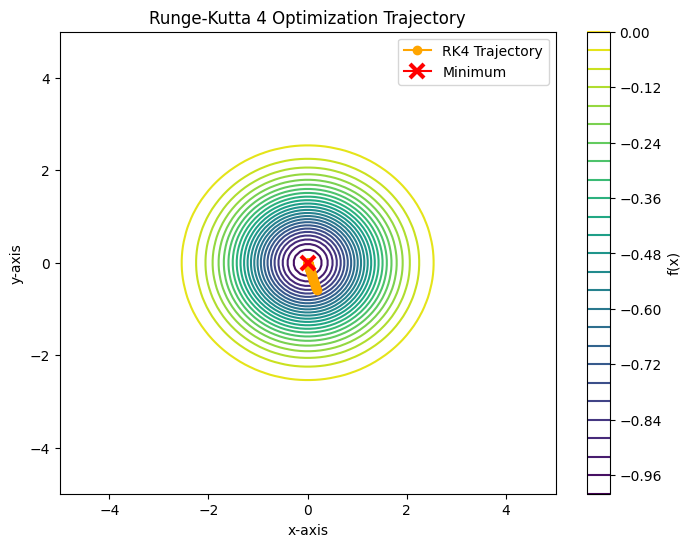

In [5]:
# Run RK4 optimizer
x_opt_rk4, f_hist_rk4, grad_norm_hist_rk4, x_hist_rk4 = runge_kutta_4(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)

# Plot RK4 trajectory
plt.figure(figsize=(8, 6))

# Function landscape
plt.contour(X, Y, Z, levels=30, cmap='viridis')

# RK4 trajectory
x_coords_rk4 = [x[0].item() for x in x_hist_rk4]
y_coords_rk4 = [x[1].item() for x in x_hist_rk4]
plt.plot(x_coords_rk4, y_coords_rk4, marker='o', color='orange', label='RK4 Trajectory')

# Minimizer
plt.plot(0, 0, marker='x', color='red', markersize=10, markeredgewidth=3, label='Minimum')

plt.colorbar(label='f(x)')
plt.title('Runge-Kutta 4 Optimization Trajectory')
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.legend()
plt.show()

In [15]:
print("GD iterations:", len(f_hist1))
print("First few GD f(x):", [fx.item() for fx in f_hist1[:5]])
print("First few GD grad norms:", [g.item() for g in grad_norm_hist1[:5]])

GD iterations: 64
First few GD f(x): [-0.823165237903595, -0.8488442301750183, -0.8717620372772217, -0.8919423222541809, -0.9094964265823364]
First few GD grad norms: [0.513536810874939, 0.4859655499458313, 0.45672139525413513, 0.4265570342540741, 0.39615681767463684]


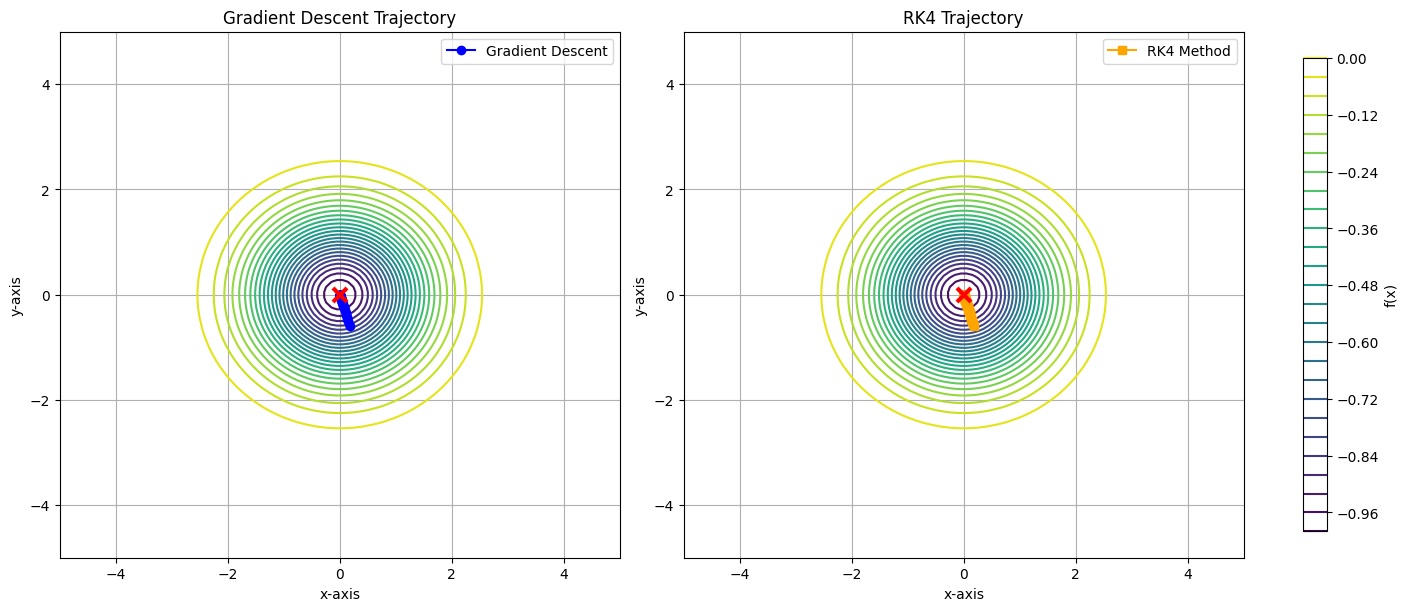

In [20]:
# Comparing Runge-Kutta 4 to Gradient Descent
# Use constrained layout to handle spacing properly
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

# --- GD Plot ---
contour1 = axes[0].contour(X, Y, Z, levels=30, cmap='viridis')
x_coords_gd = [x[0].item() for x in x_hist1]
y_coords_gd = [x[1].item() for x in x_hist1]
axes[0].plot(x_coords_gd, y_coords_gd, marker='o', color='blue', label='Gradient Descent')
axes[0].plot(0, 0, marker='x', color='red', markersize=10, markeredgewidth=3)
axes[0].set_title('Gradient Descent Trajectory')
axes[0].set_xlabel('x-axis')
axes[0].set_ylabel('y-axis')
axes[0].legend()
axes[0].grid(True)

# --- RK4 Plot ---
contour2 = axes[1].contour(X, Y, Z, levels=30, cmap='viridis')
x_coords_rk4 = [x[0].item() for x in x_hist_rk4]
y_coords_rk4 = [x[1].item() for x in x_hist_rk4]
axes[1].plot(x_coords_rk4, y_coords_rk4, marker='s', color='orange', label='RK4 Method')
axes[1].plot(0, 0, marker='x', color='red', markersize=10, markeredgewidth=3)
axes[1].set_title('RK4 Trajectory')
axes[1].set_xlabel('x-axis')
axes[1].set_ylabel('y-axis')
axes[1].legend()
axes[1].grid(True)

# Shared colorbar
fig.colorbar(contour1, ax=axes, shrink=0.9, label='f(x)')

plt.show()

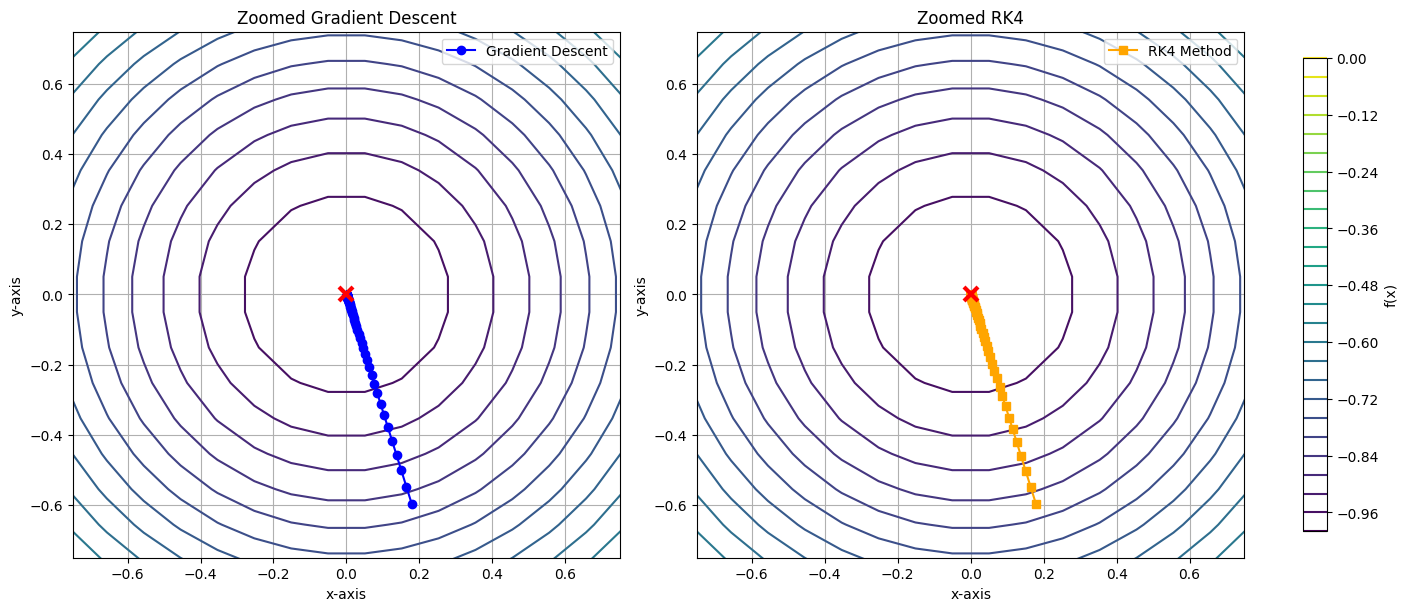

In [22]:
# Zoomed in trajectory

# Compute zoom range (e.g. ±0.5 around final point)
zoom_margin = 0.75

# Get final x/y for GD and RK4
x_final_gd, y_final_gd = x_coords_gd[-1], y_coords_gd[-1]
x_final_rk4, y_final_rk4 = x_coords_rk4[-1], y_coords_rk4[-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

# --- Zoomed GD Plot ---
contour1 = axes[0].contour(X, Y, Z, levels=30, cmap='viridis')
axes[0].plot(x_coords_gd, y_coords_gd, marker='o', color='blue', label='Gradient Descent')
axes[0].plot(0, 0, marker='x', color='red', markersize=10, markeredgewidth=3)
axes[0].set_title('Zoomed Gradient Descent')
axes[0].set_xlabel('x-axis')
axes[0].set_ylabel('y-axis')
axes[0].set_xlim(x_final_gd - zoom_margin, x_final_gd + zoom_margin)
axes[0].set_ylim(y_final_gd - zoom_margin, y_final_gd + zoom_margin)
axes[0].legend()
axes[0].grid(True)

# --- Zoomed RK4 Plot ---
contour2 = axes[1].contour(X, Y, Z, levels=30, cmap='viridis')
axes[1].plot(x_coords_rk4, y_coords_rk4, marker='s', color='orange', label='RK4 Method')
axes[1].plot(0, 0, marker='x', color='red', markersize=10, markeredgewidth=3)
axes[1].set_title('Zoomed RK4')
axes[1].set_xlabel('x-axis')
axes[1].set_ylabel('y-axis')
axes[1].set_xlim(x_final_rk4 - zoom_margin, x_final_rk4 + zoom_margin)
axes[1].set_ylim(y_final_rk4 - zoom_margin, y_final_rk4 + zoom_margin)
axes[1].legend()
axes[1].grid(True)

# Shared colorbar
fig.colorbar(contour1, ax=axes, shrink=0.9, label='f(x)')

plt.show()

Min f_vals_gd: -0.9999995827664866
Min f_vals_rk4: -0.9999995827664866
Max f_vals_gd: -0.823165237902595
Max f_vals_rk4: -0.823165237902595


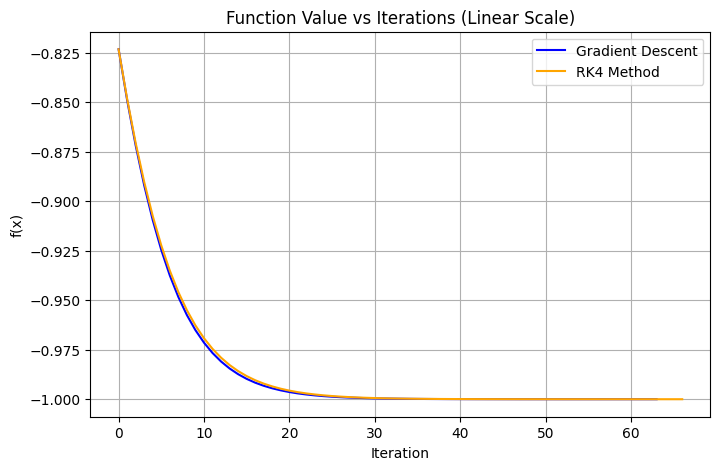

In [13]:
# Function Value vs Iterations

epsilon = 1e-12  # Small offset to avoid log(0)

f_vals_gd = [fx.item() + epsilon for fx in f_hist1]
f_vals_rk4 = [fx.item() + epsilon for fx in f_hist_rk4]
print("Min f_vals_gd:", min(f_vals_gd))
print("Min f_vals_rk4:", min(f_vals_rk4))
print("Max f_vals_gd:", max(f_vals_gd))
print("Max f_vals_rk4:", max(f_vals_rk4))
plt.figure(figsize=(8, 5))
plt.plot(f_vals_gd, label='Gradient Descent', color='blue')
plt.plot(f_vals_rk4, label='RK4 Method', color='orange')
# no log scale
plt.title('Function Value vs Iterations (Linear Scale)')
plt.xlabel('Iteration')
plt.ylabel('f(x)')
plt.legend()
plt.grid(True)
plt.show()



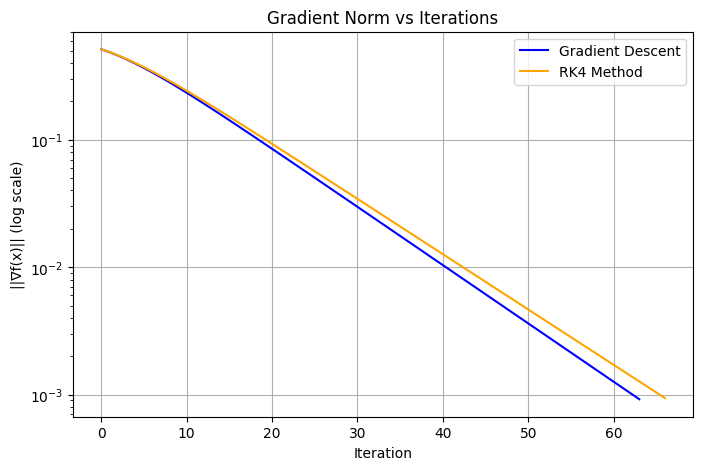

In [14]:
# Gradient Norm vs. Iterations

# Detach gradient norms
grad_norms_gd = [g.item() for g in grad_norm_hist1]
grad_norms_rk4 = [g.item() for g in grad_norm_hist_rk4]

plt.figure(figsize=(8, 5))
plt.plot(grad_norms_gd, label='Gradient Descent', color='blue')
plt.plot(grad_norms_rk4, label='RK4 Method', color='orange')
plt.yscale('log')
plt.title('Gradient Norm vs Iterations')
plt.xlabel('Iteration')
plt.ylabel('||∇f(x)|| (log scale)')
plt.legend()
plt.grid(True)
plt.show()